# ITRI625 Project – Phishing Email Detection
**Dataset:** Phishing Email Dataset (Kaggle) · **Model:** TF-IDF + Neural Network (MLP) · **Task:** classify an email as *Phishing* or *Safe*

Steps: 1 Load data → 2 Split (train/val/test) → 3 TF-IDF → 4 Model → 5 Train with logging + early stopping → 6 Graphs → 7 Test evaluation → 8 Explainability (XAI) → 9 Save model → 10 Generate theory report

In [1]:
import os, json, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             average_precision_score)
from phish_utils import explain
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
DATA_PATH = "Phishing_Email.csv"   # <- put the downloaded Kaggle CSV next to this notebook
STUDENTS = [("Your Name Surname", "St number"), ("", "")]   # <- fill in (2nd student optional)
FLIP_NUMERIC_LABELS = False        # only if your CSV has 0/1 labels AND the examples printed below look reversed
os.makedirs("figures", exist_ok=True); os.makedirs("model", exist_ok=True)
def save_fig(name):                # saves the current figure as a PNG so you can paste it into your report
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")


## 1. Load and inspect the dataset

Columns: ['text_combined', 'label']
Emails after cleaning: 82078
label_name
Phishing Email    42845
Safe Email        39233
Name: count, dtype: int64

--- 2 examples labelled 'Phishing Email' ---
  * link dwl g 510 802 11 g wireless pci lan adapter 39 85 39 85 dwl g 510 high speed 2 4 ghz 802 11 g wireless pci lan adapter ieee 802 11 g standardupto
  * indemand payperview movies sports wed 15 sep 2004 11 33 14 0500 hi cable tv subscriber per per view filters lets get pay per view mature channels movi

--- 2 examples labelled 'Safe Email' ---
  * hpl nom may 25 2001 see attached file hplno 525 xls hplno 525 xls
  * nom actual vols 24 th forwarded sabrae zajac hou ect 05 30 2001 12 07 pm enron capital trade resources corp eileen ponton 05 29 2001 08 37 davilal txu


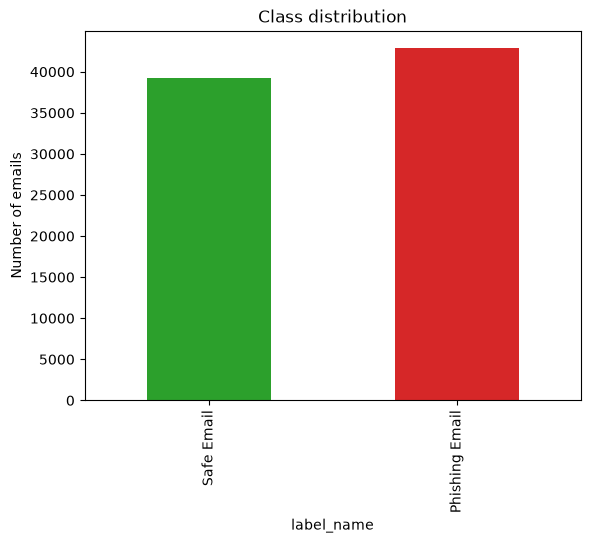

,text,label_raw,label,label_name
0,hpl nom may 25 2001 see attached file hplno 52...,0,0,Safe Email
1,nom actual vols 24 th forwarded sabrae zajac h...,0,0,Safe Email
2,enron actuals march 30 april 1 201 estimated a...,0,0,Safe Email
3,hpl nom may 30 2001 see attached file hplno 53...,0,0,Safe Email
4,hpl nom june 1 2001 see attached file hplno 60...,0,0,Safe Email


In [2]:
df = pd.read_csv(DATA_PATH)
print("Columns:", list(df.columns))

# find the text column and the label column automatically
text_col  = [c for c in df.columns if "text" in c.lower() or "body" in c.lower()][0]
label_col = [c for c in df.columns if "type" in c.lower() or "label" in c.lower()][0]
df = df[[text_col, label_col]].dropna().drop_duplicates(subset=text_col)
df.columns = ["text", "label_raw"]

# text labels (e.g. "Phishing Email" / "Safe Email") OR numeric labels (0/1, 1 = phishing)
if pd.api.types.is_numeric_dtype(df["label_raw"]):
    df["label"] = df["label_raw"].astype(int)
    if FLIP_NUMERIC_LABELS: df["label"] = 1 - df["label"]
else:
    df["label"] = df["label_raw"].astype(str).str.lower().str.contains("phish").astype(int)   # 1 = phishing, 0 = safe
df["label_name"] = df["label"].map({1: "Phishing Email", 0: "Safe Email"})

print("Emails after cleaning:", len(df))
print(df["label_name"].value_counts())

# LABEL CHECK: read these examples. 'Phishing Email' ones should look like scams, 'Safe Email' ones like normal mail.
for name in ["Phishing Email", "Safe Email"]:
    print(f"\n--- 2 examples labelled '{name}' ---")
    for t in df[df.label_name == name]["text"].head(2): print("  *", str(t)[:150].replace("\n", " "))

df["label_name"].value_counts().reindex(["Safe Email", "Phishing Email"]).plot(kind="bar", color=["tab:green", "tab:red"], title="Class distribution")
plt.ylabel("Number of emails"); save_fig("01_class_distribution"); plt.show()
df.head()

## 2. Split the dataset: train (70%) / validation (15%) / test (15%)

In [3]:
X_train_txt, X_tmp, y_train, y_tmp = train_test_split(
    df["text"], df["label"], test_size=0.30, stratify=df["label"], random_state=SEED)
X_val_txt, X_test_txt, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print(f"Train: {len(y_train)} | Validation: {len(y_val)} | Test: {len(y_test)}")
print("Phishing share  train/val/test:",
      round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Train: 57454 | Validation: 12312 | Test: 12312
Phishing share  train/val/test: 0.522 0.522 0.522


## 3. Convert text to numbers (TF-IDF) – fitted on the training set only

In [4]:
vec = TfidfVectorizer(lowercase=True, stop_words="english", max_features=5000, sublinear_tf=True)
X_train = vec.fit_transform(X_train_txt)
X_val   = vec.transform(X_val_txt)
X_test  = vec.transform(X_test_txt)
print("Feature matrix shape (emails x words):", X_train.shape)

Feature matrix shape (emails x words): (57454, 5000)


## 4. Model: Multi-Layer Perceptron (neural network)
`TF-IDF (5000 inputs) → Dense 64 neurons + ReLU → 1 neuron + Sigmoid → phishing probability`. Loss = binary cross-entropy, optimiser = Adam.

In [5]:
model = MLPClassifier(hidden_layer_sizes=(64,), activation="relu", solver="adam",
                      learning_rate_init=0.001, batch_size=64, alpha=1e-4, random_state=SEED)
print("Architecture: TF-IDF inputs -> 64 neurons (ReLU) -> 1 neuron (Sigmoid)")

Architecture: TF-IDF inputs -> 64 neurons (ReLU) -> 1 neuron (Sigmoid)


## 5. Training loop with metric logging and early stopping (patience)
One epoch at a time. After **every epoch** all metrics are logged for train and validation sets. Training stops when validation loss has not improved for `PATIENCE` epochs, and the best model is restored.

In [6]:
def evaluate(m, X, y):
    p = m.predict_proba(X)[:, 1]
    pred = (p >= 0.5).astype(int)
    return {"loss": log_loss(y, p), "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "auc_roc": roc_auc_score(y, p)}

MAX_EPOCHS, PATIENCE = 30, 3
best_val_loss, best_epoch, wait, best_model = np.inf, 0, 0, None
log = []

for epoch in range(1, MAX_EPOCHS + 1):
    model.partial_fit(X_train, y_train, classes=[0, 1])        # one epoch
    tr, va = evaluate(model, X_train, y_train), evaluate(model, X_val, y_val)
    log.append({"epoch": epoch, **{f"train_{k}": v for k, v in tr.items()},
                **{f"val_{k}": v for k, v in va.items()}})
    print(f"Epoch {epoch:02d} | train_loss {tr['loss']:.4f} val_loss {va['loss']:.4f} | "
          f"val_acc {va['accuracy']:.4f} val_prec {va['precision']:.4f} val_rec {va['recall']:.4f} "
          f"val_f1 {va['f1']:.4f} val_auc {va['auc_roc']:.4f}")
    if va["loss"] < best_val_loss:                              # improvement
        best_val_loss, best_epoch, wait = va["loss"], epoch, 0
        best_model = copy.deepcopy(model)
    else:                                                        # no improvement
        wait += 1
        print(f"   no improvement ({wait}/{PATIENCE})")
        if wait >= PATIENCE:
            print(f"EARLY STOPPING at epoch {epoch}. Best epoch = {best_epoch}")
            break

stop_epoch = epoch
model = best_model                                               # restore best weights
n_params = sum(c.size for c in model.coefs_) + sum(b.size for b in model.intercepts_)
print("Trainable parameters:", n_params)
log_df = pd.DataFrame(log)
log_df.to_csv("training_log.csv", index=False)
log_df.round(4)

Epoch 01 | train_loss 0.0331 val_loss 0.0462 | val_acc 0.9839 val_prec 0.9834 val_rec 0.9858 val_f1 0.9846 val_auc 0.9985
Epoch 02 | train_loss 0.0193 val_loss 0.0414 | val_acc 0.9846 val_prec 0.9848 val_rec 0.9858 val_f1 0.9853 val_auc 0.9987
Epoch 03 | train_loss 0.0130 val_loss 0.0433 | val_acc 0.9839 val_prec 0.9843 val_rec 0.9849 val_f1 0.9846 val_auc 0.9987
   no improvement (1/3)
Epoch 04 | train_loss 0.0091 val_loss 0.0475 | val_acc 0.9835 val_prec 0.9843 val_rec 0.9841 val_f1 0.9842 val_auc 0.9986
   no improvement (2/3)
Epoch 05 | train_loss 0.0066 val_loss 0.0525 | val_acc 0.9829 val_prec 0.9844 val_rec 0.9829 val_f1 0.9836 val_auc 0.9985
   no improvement (3/3)
EARLY STOPPING at epoch 5. Best epoch = 2
Trainable parameters: 320129


,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,train_auc_roc,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_auc_roc
0,1,0.0331,0.9911,0.9896,0.9933,0.9914,0.9992,0.0462,0.9839,0.9834,0.9858,0.9846,0.9985
1,2,0.0193,0.9952,0.9943,0.9966,0.9955,0.9997,0.0414,0.9846,0.9848,0.9858,0.9853,0.9987
2,3,0.0130,0.9973,0.9970,0.9977,0.9974,0.9999,0.0433,0.9839,0.9843,0.9849,0.9846,0.9987
3,4,0.0091,0.9983,0.9983,0.9985,0.9984,0.9999,0.0475,0.9835,0.9843,0.9841,0.9842,0.9986
4,5,0.0066,0.9989,0.9990,0.9990,0.9990,0.9999,0.0525,0.9829,0.9844,0.9829,0.9836,0.9985


## 6. Training graphs (loss and metrics per epoch)

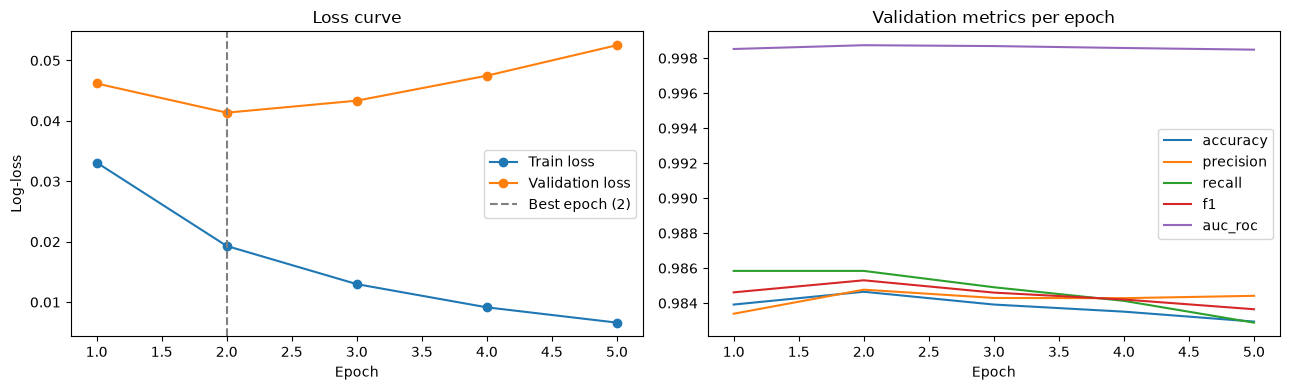

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(log_df.epoch, log_df.train_loss, label="Train loss", marker="o")
ax[0].plot(log_df.epoch, log_df.val_loss, label="Validation loss", marker="o")
ax[0].axvline(best_epoch, color="gray", ls="--", label=f"Best epoch ({best_epoch})")
ax[0].set_title("Loss curve"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Log-loss"); ax[0].legend()
for m in ["accuracy", "precision", "recall", "f1", "auc_roc"]:
    ax[1].plot(log_df.epoch, log_df[f"val_{m}"], label=m)
ax[1].set_title("Validation metrics per epoch"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); save_fig("02_loss_and_metric_curves"); plt.show()

## 7. Final evaluation on the unseen TEST set

In [8]:
test = evaluate(model, X_test, y_test)
pd.DataFrame(test, index=["Test set"]).T.round(4)

,Test set
loss,0.0416
accuracy,0.9853
precision,0.9857
recall,0.9862
f1,0.9859
auc_roc,0.9987


              precision    recall  f1-score   support

        Safe     0.9849    0.9844    0.9846      5885
    Phishing     0.9857    0.9862    0.9859      6427

    accuracy                         0.9853     12312
   macro avg     0.9853    0.9853    0.9853     12312
weighted avg     0.9853    0.9853    0.9853     12312



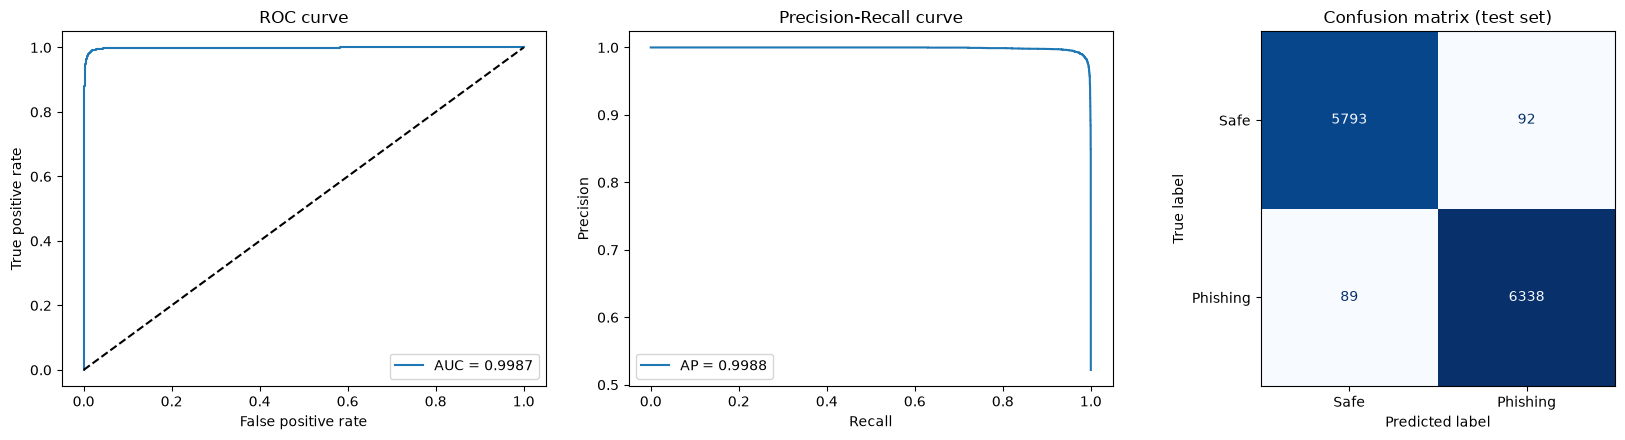

In [9]:
p_test = model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= 0.5).astype(int)
print(classification_report(y_test, pred_test, target_names=["Safe", "Phishing"], digits=4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
# ROC curve
fpr, tpr, _ = roc_curve(y_test, p_test)
ax[0].plot(fpr, tpr, label=f"AUC = {test['auc_roc']:.4f}"); ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set_title("ROC curve"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
# Precision-Recall curve
prec, rec, _ = precision_recall_curve(y_test, p_test)
ax[1].plot(rec, prec, label=f"AP = {average_precision_score(y_test, p_test):.4f}")
ax[1].set_title("Precision-Recall curve"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
# Confusion matrix
cm = confusion_matrix(y_test, pred_test)
ConfusionMatrixDisplay(cm, display_labels=["Safe", "Phishing"]).plot(ax=ax[2], cmap="Blues", colorbar=False)
ax[2].set_title("Confusion matrix (test set)")
plt.tight_layout(); save_fig("03_roc_pr_confusion"); plt.show()

## 8. Additional feature – Explainable AI (XAI)
Word-occlusion: remove each important word and measure how the phishing score (log-odds) drops. **Red = pushes towards phishing, green = pushes towards safe.**

Email (first 300 chars): herb dick erkantikencelibereketkalipcom sbeewel naughty schoolgirl gets pierced pussy fingered drilled cock tue 05 aug 2008 230607 0000 porn reviews ...
Predicted phishing probability: 0.998


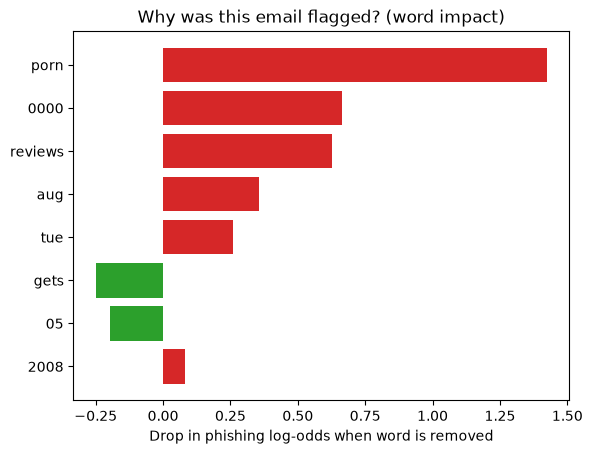

In [10]:
idx = int(np.where(y_test.values == 1)[0][0])               # first phishing email in the test set
sample = X_test_txt.iloc[idx]
prob, top = explain(model, vec, sample, top_k=8)
print("Email (first 300 chars):", sample[:300].replace("\n", " "), "...")
print(f"Predicted phishing probability: {prob:.3f}")
words, impacts = zip(*top)
plt.barh(words[::-1], impacts[::-1], color=["tab:red" if i > 0 else "tab:green" for i in impacts[::-1]])
plt.title("Why was this email flagged? (word impact)")
plt.xlabel("Drop in phishing log-odds when word is removed"); save_fig("04_xai_word_impact"); plt.show()

## 9. Save the model (used by the Flask API)

In [11]:
joblib.dump(model, "model/model.joblib")
joblib.dump(vec, "model/vectorizer.joblib")
metrics = {"test": test, "best_epoch": best_epoch, "stop_epoch": stop_epoch,
           "confusion_matrix": cm.tolist(), "n_train": len(y_train), "n_val": len(y_val), "n_test": len(y_test)}
json.dump(metrics, open("model/metrics.json", "w"), indent=2)
print("Saved: model/model.joblib, model/vectorizer.joblib, model/metrics.json, training_log.csv")

Saved: model/model.joblib, model/vectorizer.joblib, model/metrics.json, training_log.csv


## 9b. Architecture diagram (used in the theory report, section 3.2)

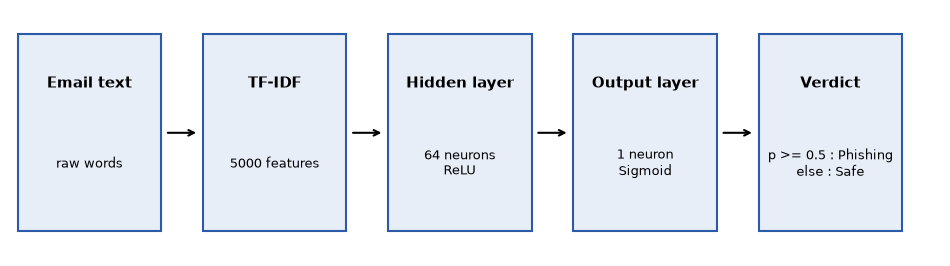

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.2)); ax.axis("off")
boxes = [("Email text", "raw words"), ("TF-IDF", f"{X_train.shape[1]} features"), ("Hidden layer", "64 neurons\nReLU"),
         ("Output layer", "1 neuron\nSigmoid"), ("Verdict", "p >= 0.5 : Phishing\nelse : Safe")]
for i, (t, s) in enumerate(boxes):
    x = i * 2.45
    ax.add_patch(plt.Rectangle((x, 0.2), 1.9, 1.6, fc="#e8eef8", ec="#2b5ba8", lw=1.5))
    ax.text(x + 0.95, 1.4, t, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(x + 0.95, 0.75, s, ha="center", va="center", fontsize=9)
    if i < len(boxes) - 1: ax.annotate("", xy=(x + 2.4, 1.0), xytext=(x + 1.95, 1.0), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_xlim(-0.1, 12.2); ax.set_ylim(0, 2)
save_fig("05_architecture"); plt.show()

## 10. Generate the theory report (numbers filled in automatically from this run)

In [13]:
last = log_df.iloc[best_epoch - 1]
gap = last.val_loss - last.train_loss
if gap < 0.05:
    gap_txt = "The two curves are close together, so the model generalises well and is not overfitting."
elif gap < 0.15:
    gap_txt = "There is a small gap between training and validation loss; early stopping prevented it from growing, so overfitting is limited."
else:
    gap_txt = "There is a noticeable gap between training and validation loss, indicating some overfitting; early stopping stopped training at the best epoch to limit this."
if test["f1"] >= 0.95:
    verdict = "The model is highly effective at separating phishing from safe emails on unseen data, with high precision and recall."
elif test["f1"] >= 0.85:
    verdict = "The model is effective, catching most phishing emails with an acceptable number of false alarms, though there is room for improvement."
else:
    verdict = "The model is only moderately effective; more data, better features or a different model would be needed before real use."

(tn, fp), (fn, tp) = cm
tokens = {"N_TOTAL": len(df), "N_TRAIN": len(y_train), "N_VAL": len(y_val), "N_TEST": len(y_test),
          "N_FEATURES": X_train.shape[1], "N_PARAMS": f"{n_params:,}",
          "ACC": f"{test['accuracy']:.4f}", "PREC": f"{test['precision']:.4f}", "REC": f"{test['recall']:.4f}",
          "F1": f"{test['f1']:.4f}", "AUC": f"{test['auc_roc']:.4f}",
          "TN": tn, "FP": fp, "FN": fn, "TP": tp, "BEST_EPOCH": best_epoch, "STOP_EPOCH": stop_epoch,
          "TRAIN_LOSS": f"{last.train_loss:.4f}", "VAL_LOSS": f"{last.val_loss:.4f}",
          "GAP_COMMENT": gap_txt, "VERDICT": verdict}
report = open("theory_template.md", encoding="utf-8").read()
for k, v in tokens.items():
    report = report.replace(f"<<{k}>>", str(v))
open("Theory_Report.md", "w", encoding="utf-8").write(report)
print("Theory_Report.md created.")
print("Figures for the report are in the figures/ folder:", sorted(os.listdir("figures")))

Theory_Report.md created.
Figures for the report are in the figures/ folder: ['01_class_distribution.png', '02_loss_and_metric_curves.png', '03_roc_pr_confusion.png', '04_xai_word_impact.png', '05_architecture.png']


## 11. Build the theory document (Word)
Creates **Theory_Answers.docx** in the lecturer's layout, with your results and figures already inserted. Open it, check it, add your names if you skipped them above, and submit it.

In [14]:
try:
    from make_theory_docx import build
    print("Created:", build("Theory_Report.md", "Theory_Answers.docx", STUDENTS))
except ImportError:
    print("Run once in a terminal:  pip install python-docx   then re-run this cell.")

Created: Theory_Answers.docx
